# Visualização de Resultados Modal PREDEP

Notebook para gerar plots dos resultados da análise Modal usando as funções de visualização do projeto.

In [5]:
import sys
from pathlib import Path
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt

# Adicionar src ao path
sys.path.insert(0, str(Path.cwd().parent))

from src.visualization import plot_4x4_optimal_lags, plot_13x4_all_lags

## 1. Carregar Resultados Modal

In [6]:
# Diretório com resultados Modal
results_dir = Path("../results")

# Verificar arquivos disponíveis
nc_files = list(results_dir.glob("*.nc"))
print(f"Arquivos encontrados: {len(nc_files)}")
for f in nc_files:
    print(f"  - {f.name}")

Arquivos encontrados: 5
  - AAO_SON_xavier_rs.nc
  - AAO_ALL_SEASONS_xavier_rs.nc
  - AAO_DJF_xavier_rs.nc
  - AAO_MAM_xavier_rs.nc
  - AAO_JJA_xavier_rs.nc


## 2. Carregar e Combinar Dados

In [7]:
# Estações
seasons = ["DJF", "MAM", "JJA", "SON"]
mov_index = "AAO"

# Carregar dados de cada estação
all_data = []
for season in seasons:
    nc_file = results_dir / f"{mov_index}_{season}_xavier_rs.nc"
    
    if nc_file.exists():
        ds = xr.open_dataset(nc_file)
        print(f"✓ {season}: {ds.dims}")
        
        # Empilhar lags
        n_lags = len(ds.lag)
        alpha_list = []
        for lag in range(n_lags):
            alpha_data = ds[f'alpha_lag{lag}'].values
            alpha_list.append(alpha_data)
        
        alpha_stacked = np.stack(alpha_list, axis=0)
        all_data.append(alpha_stacked)
        
        # Salvar coordenadas
        if len(all_data) == 1:
            lats = ds.latitude.values
            lons = ds.longitude.values
    else:
        print(f"⚠️  {season}: arquivo não encontrado")

print(f"\nEstações carregadas: {len(all_data)}")

✓ DJF: Frozen({'latitude': 89, 'longitude': 130, 'lag': 13})
✓ MAM: Frozen({'latitude': 89, 'longitude': 130, 'lag': 13})
✓ JJA: Frozen({'latitude': 89, 'longitude': 130, 'lag': 13})
✓ SON: Frozen({'latitude': 89, 'longitude': 130, 'lag': 13})

Estações carregadas: 4


## 3. Criar Dataset Combinado

In [8]:
# Combinar em formato esperado pelas funções de plot
# Shape: (1, n_seasons, n_lags, n_lat, n_lon)
combined_alpha = np.stack(all_data, axis=0)[np.newaxis, :, :, :, :]

print(f"Shape combinado: {combined_alpha.shape}")
print(f"  mov=1, seasons={len(all_data)}, lags={n_lags}, lat={len(lats)}, lon={len(lons)}")

# Criar Dataset
ds_combined = xr.Dataset(
    {'predep_alpha': (['mov', 'season', 'lag', 'latitude', 'longitude'], combined_alpha)},
    coords={
        'mov': [mov_index],
        'season': seasons[:len(all_data)],
        'lag': list(range(n_lags)),
        'latitude': lats,
        'longitude': lons
    }
)

print(f"\nDataset criado:")
print(ds_combined)

Shape combinado: (1, 4, 13, 89, 130)
  mov=1, seasons=4, lags=13, lat=89, lon=130

Dataset criado:
<xarray.Dataset>
Dimensions:       (mov: 1, season: 4, lag: 13, latitude: 89, longitude: 130)
Coordinates:
  * mov           (mov) <U3 'AAO'
  * season        (season) <U3 'DJF' 'MAM' 'JJA' 'SON'
  * lag           (lag) int64 0 1 2 3 4 5 6 7 8 9 10 11 12
  * latitude      (latitude) float32 -33.85 -33.75 -33.65 ... -25.15 -25.05
  * longitude     (longitude) float32 -59.95 -59.85 -59.75 ... -47.15 -47.05
Data variables:
    predep_alpha  (mov, season, lag, latitude, longitude) float64 nan ... nan


## 4. Gerar Plot 4x4 (Lags Ótimos)

📊 Gerando plot 4x4 (Lags Ótimos)...
✅ Plot salvo: ../results/plots/optimal_lag_seasons_AAO_MODAL.png


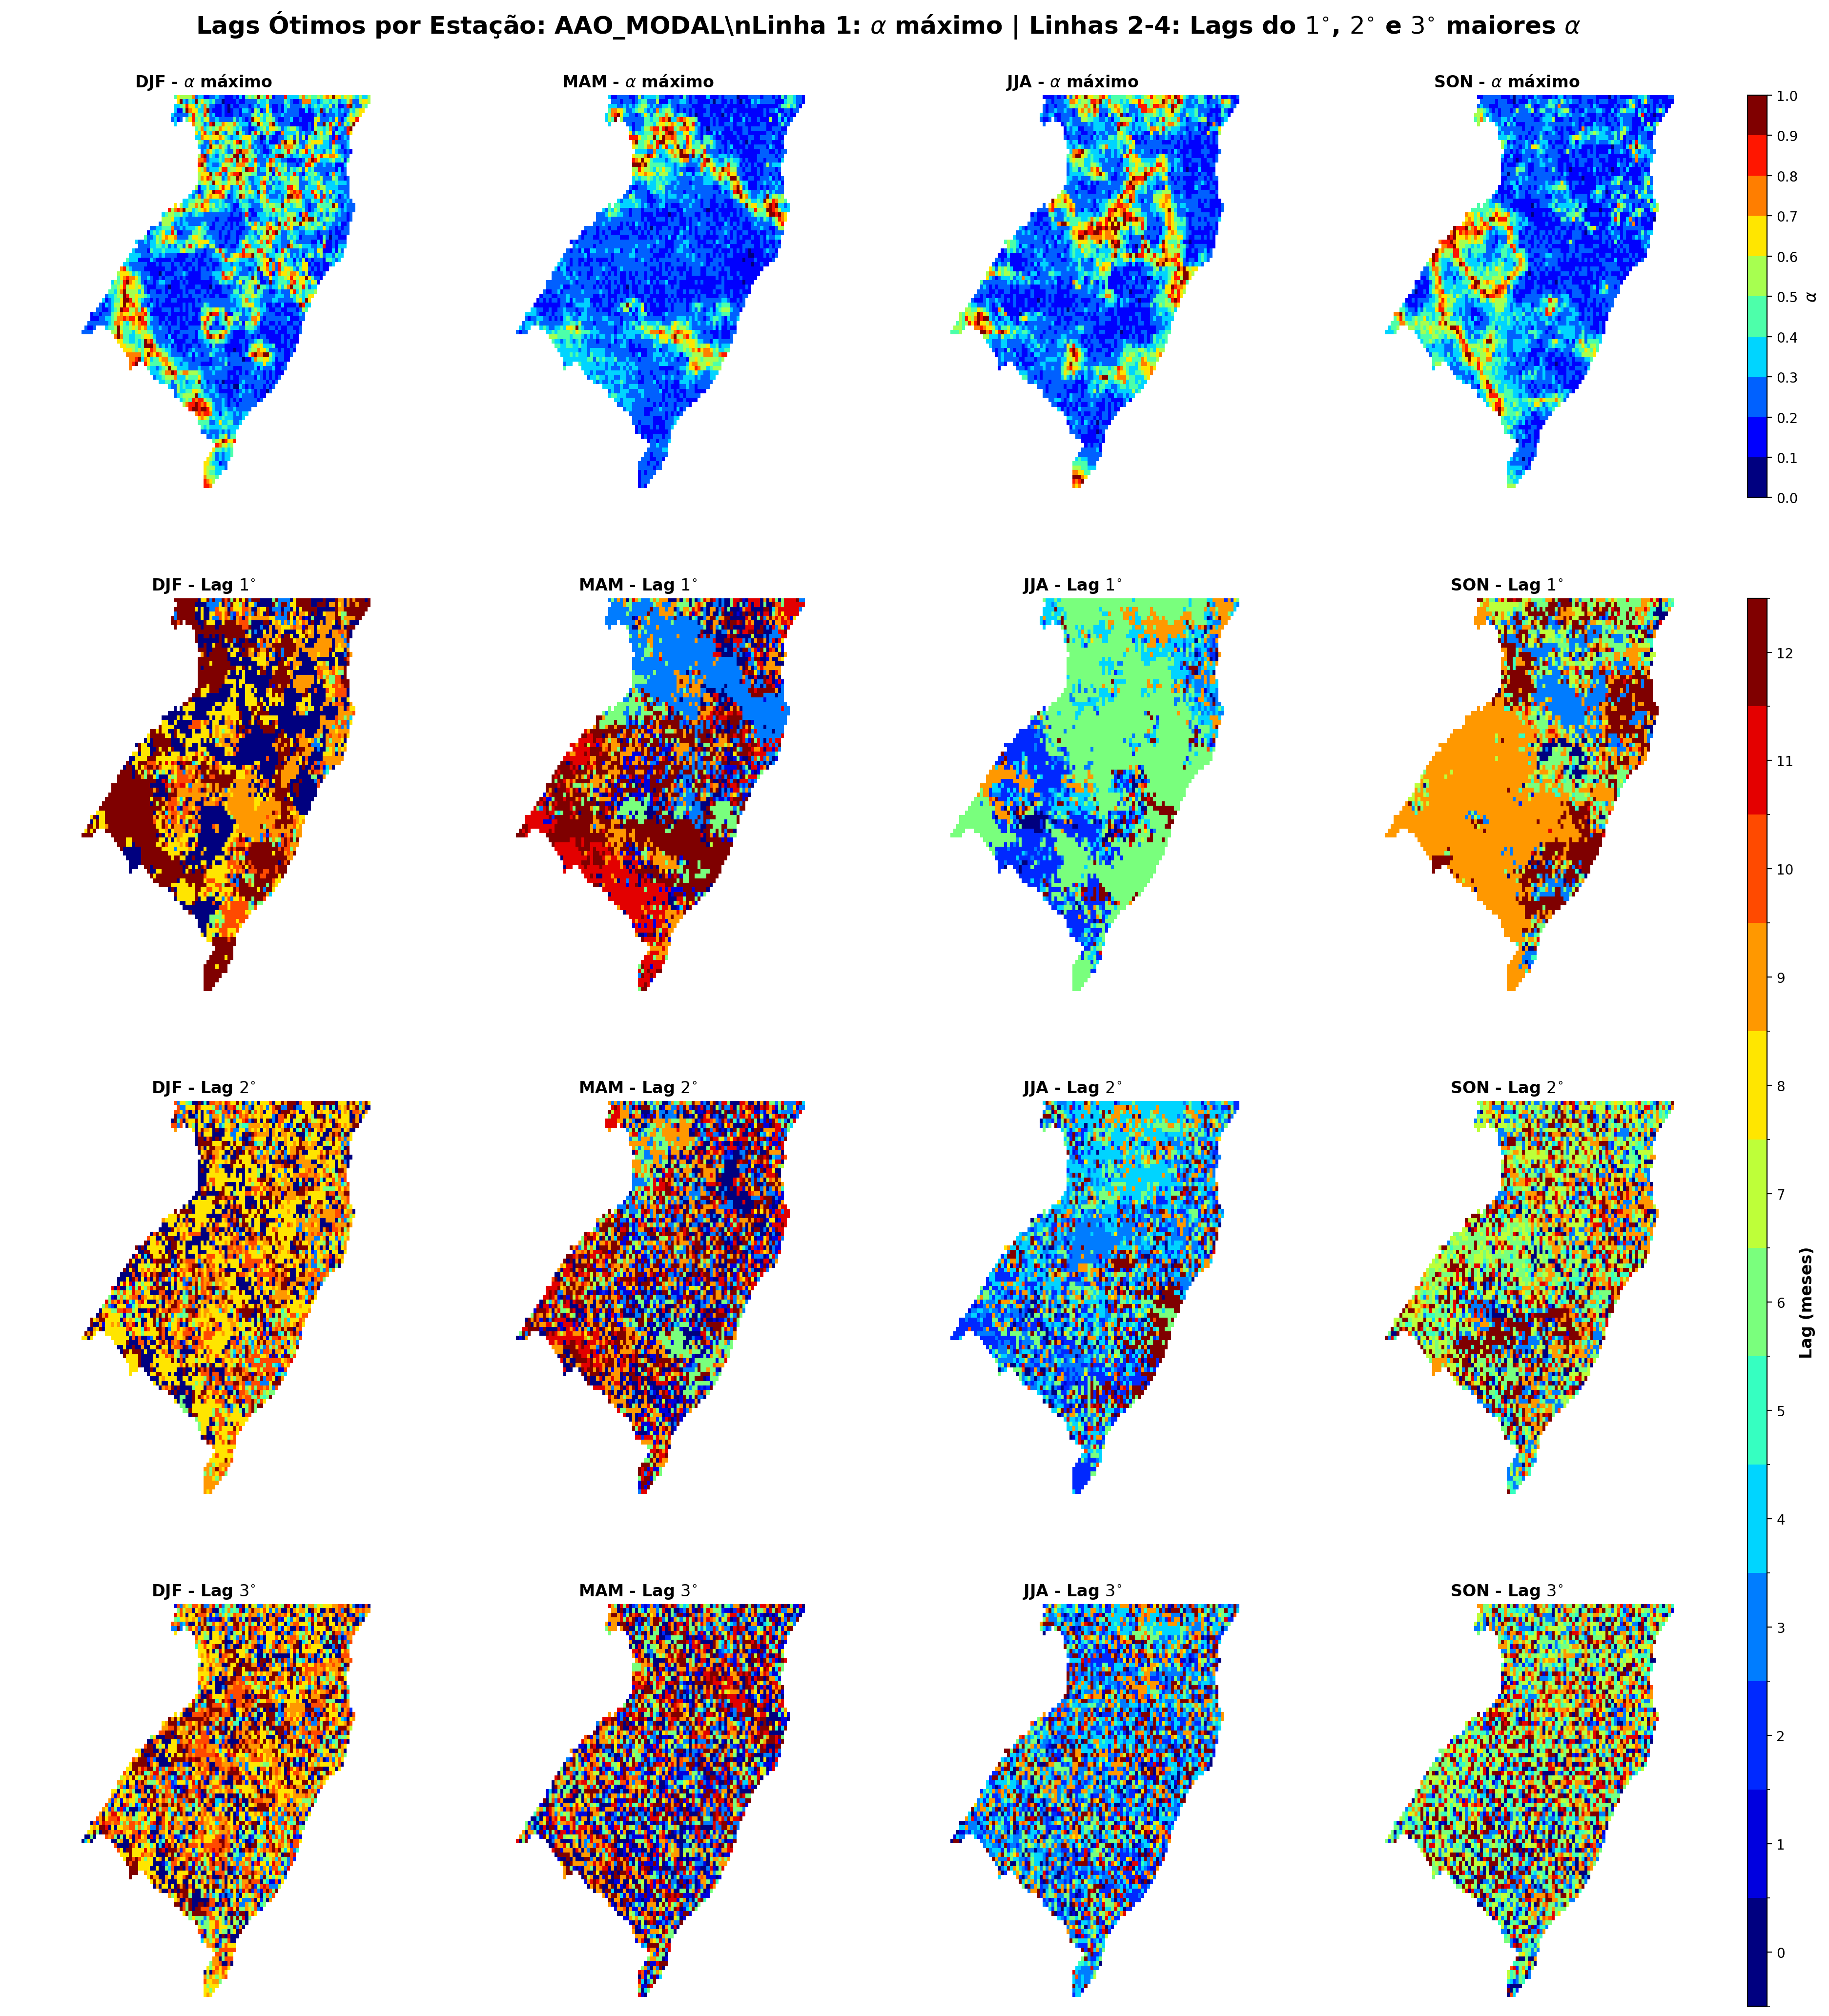

In [9]:
# Criar diretório de saída
output_dir = results_dir / "plots"
output_dir.mkdir(exist_ok=True)

print("📊 Gerando plot 4x4 (Lags Ótimos)...")
output_4x4 = plot_4x4_optimal_lags(
    ds_combined, 
    f'{mov_index}_MODAL', 
    output_dir, 
    seasons=seasons[:len(all_data)]
)

if output_4x4:
    print(f"✅ Plot salvo: {output_4x4}")
    
    # Exibir no notebook
    from IPython.display import Image, display
    display(Image(filename=str(output_4x4)))
else:
    print("⚠️  Erro ao gerar plot 4x4")

## 5. Gerar Plot 13x4 (Todos os Lags)

📊 Gerando plot 13x4 (Todos os Lags)...
✅ Plot salvo: ../results/plots/predep_13x4_grid_AAO_MODAL.png


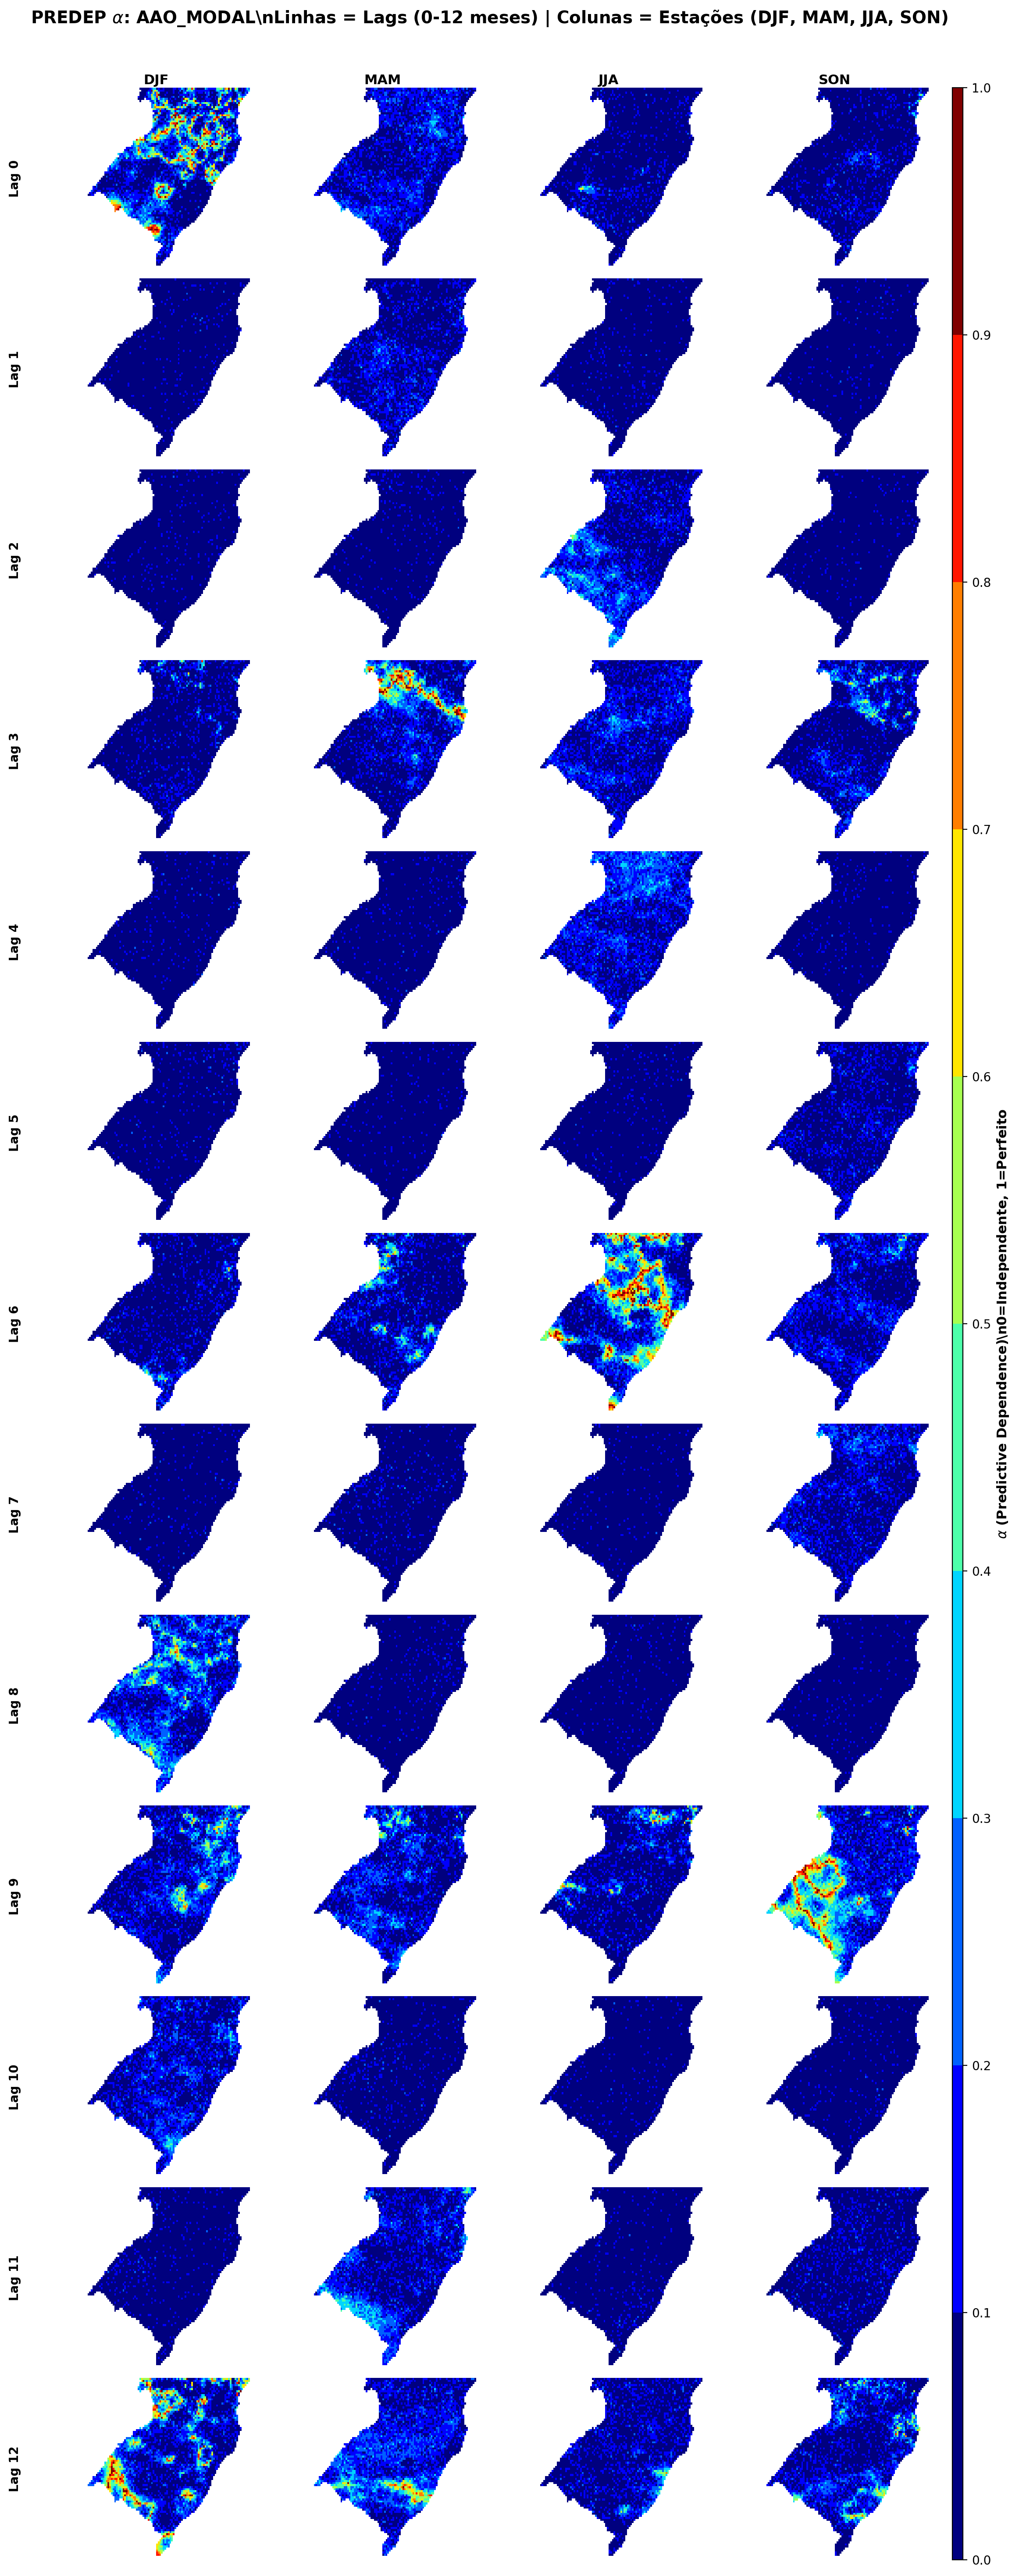

In [10]:
print("📊 Gerando plot 13x4 (Todos os Lags)...")
output_13x4 = plot_13x4_all_lags(
    ds_combined, 
    f'{mov_index}_MODAL', 
    output_dir, 
    seasons=seasons[:len(all_data)]
)

if output_13x4:
    print(f"✅ Plot salvo: {output_13x4}")
    
    # Exibir no notebook
    from IPython.display import Image, display
    display(Image(filename=str(output_13x4)))
else:
    print("⚠️  Erro ao gerar plot 13x4")

## 6. Estatísticas dos Resultados

In [ ]:
print("📊 ESTATÍSTICAS POR ESTAÇÃO\n" + "="*60)

for season_idx, season in enumerate(seasons[:len(all_data)]):
    print(f"\n{season}:")
    
    for lag in range(n_lags):
        data = ds_combined['predep_alpha'].isel(mov=0, season=season_idx, lag=lag).values
        
        valid_points = np.sum(~np.isnan(data))
        
        if valid_points > 0:
            mean_alpha = np.nanmean(data)
            max_alpha = np.nanmax(data)
            min_alpha = np.nanmin(data)
            significant = np.sum(data > 0.05)
            
            print(f"  Lag {lag:2d}: {valid_points:4d} válidos | "
                  f"α médio={mean_alpha:.3f} | "
                  f"α máx={max_alpha:.3f} | "
                  f"α mín={min_alpha:.3f} | "
                  f">0.05: {significant:4d}")
        else:
            print(f"  Lag {lag:2d}: Sem dados válidos")

## 7. Análise de Lags Ótimos

In [ ]:
print("🎯 LAGS ÓTIMOS POR ESTAÇÃO\n" + "="*60)

for season_idx, season in enumerate(seasons[:len(all_data)]):
    alpha_data = ds_combined['predep_alpha'].isel(mov=0, season=season_idx).values
    
    # Encontrar lag com maior α médio
    mean_alphas = np.nanmean(alpha_data, axis=(1, 2))
    optimal_lag = np.nanargmax(mean_alphas)
    optimal_alpha = mean_alphas[optimal_lag]
    
    # Encontrar lag com maior α máximo
    max_alphas = np.nanmax(alpha_data, axis=(1, 2))
    max_lag = np.nanargmax(max_alphas)
    max_alpha = max_alphas[max_lag]
    
    print(f"\n{season}:")
    print(f"  Lag ótimo (α médio): Lag {optimal_lag} (α={optimal_alpha:.3f})")
    print(f"  Lag ótimo (α máximo): Lag {max_lag} (α={max_alpha:.3f})")
    
    # Top 3 lags por α médio
    top3_indices = np.argsort(mean_alphas)[-3:][::-1]
    print(f"  Top 3 lags (α médio):")
    for rank, lag_idx in enumerate(top3_indices, 1):
        print(f"    {rank}º: Lag {lag_idx} (α={mean_alphas[lag_idx]:.3f})")

## 8. Salvar Dataset Combinado

In [ ]:
# Salvar dataset combinado para uso futuro
combined_file = results_dir / f"{mov_index}_ALL_SEASONS_combined.nc"
ds_combined.to_netcdf(combined_file)
print(f"💾 Dataset combinado salvo: {combined_file}")
print(f"   Tamanho: {combined_file.stat().st_size / 1024 / 1024:.2f} MB")

## 9. Resumo Final

In [ ]:
print("\n" + "="*60)
print("✅ VISUALIZAÇÃO CONCLUÍDA")
print("="*60)
print(f"\n📁 Arquivos gerados em: {output_dir}")
print(f"\n📊 Plots:")
if output_4x4:
    print(f"  - 4x4 (Lags Ótimos): {output_4x4.name}")
if output_13x4:
    print(f"  - 13x4 (Todos Lags): {output_13x4.name}")
print(f"\n💾 Dataset combinado: {combined_file.name}")
print(f"\n🎯 Análise: {mov_index}")
print(f"   Estações: {', '.join(seasons[:len(all_data)])}")
print(f"   Lags: 0-{n_lags-1}")
print(f"   Grade: {len(lats)} lat × {len(lons)} lon")